# Intel Scene Image Classification

This is a CNN classification project.

We have outdoor photos in 6 classes: buildings, forest, glacier, mountain, sea and street. The images are already split into a train folder and a test folder. There is also a seg_pred folder with photos that have no label.

I will train two models on the same split. The first is our own CNN. The second is EfficientNetB0. These are normal 224 photos of places, and EfficientNetB0 is a strong transfer model for that without being too heavy. Validation comes from the train folder. The test folder is only for the final scores. I will compare the two models, save the model, and try the transfer model on a few unlabeled photos.


In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("puneet6060/intel-image-classification")

print("Path to dataset files:", path)


Using Colab cache for faster access to the 'intel-image-classification' dataset.
Path to dataset files: /kaggle/input/intel-image-classification


In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from PIL import Image
from tensorflow.keras import layers
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay, accuracy_score, precision_score, recall_score, f1_score)

tf.keras.utils.set_random_seed(42)

SCENE_CLASSES = {"buildings", "forest", "glacier", "mountain", "sea", "street"}


def find_class_root(root, kind):
    for current, dirnames, _ in os.walk(root):
        if SCENE_CLASSES <= set(dirnames) and kind in current.replace("\\", "/").lower():
            return current


train_dir = find_class_root(path, "train")
test_dir = find_class_root(path, "test")
class_names = sorted([f for f in os.listdir(train_dir) if os.path.isdir(os.path.join(train_dir, f))])
print("Train:", train_dir)
print("Test :", test_dir)
print(class_names)
for name in class_names:
    print(name, "->", len(os.listdir(os.path.join(train_dir, name))))


Train: /kaggle/input/intel-image-classification/seg_train/seg_train
Test : /kaggle/input/intel-image-classification/seg_test/seg_test
['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
buildings -> 2191
forest -> 2271
glacier -> 2404
mountain -> 2512
sea -> 2274
street -> 2382


buildings -> (150, 150) RGB
forest -> (150, 150) RGB
glacier -> (150, 150) RGB
mountain -> (150, 150) RGB
sea -> (150, 150) RGB
street -> (150, 150) RGB


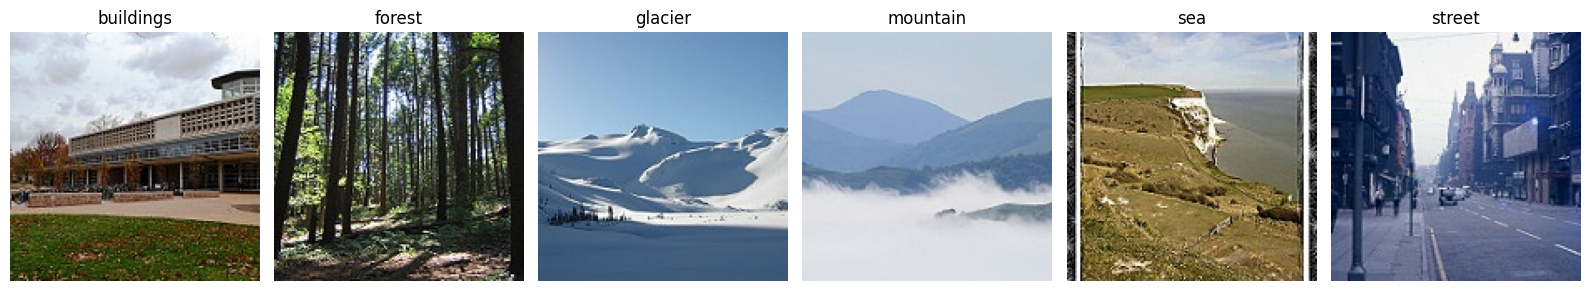

In [ ]:
plt.figure(figsize=(16, 4))
for i, class_name in enumerate(class_names):
    class_path = os.path.join(train_dir, class_name)
    image_path = os.path.join(class_path, os.listdir(class_path)[0])
    image = plt.imread(image_path)
    plt.subplot(1, len(class_names), i + 1)
    plt.imshow(image)
    plt.title(class_name)
    plt.axis("off")
    print(class_name, "->", Image.open(image_path).size, Image.open(image_path).mode)
plt.tight_layout()
plt.show()


In [ ]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir, validation_split=0.2, subset="training", seed=42,
    image_size=IMG_SIZE, batch_size=BATCH_SIZE, label_mode="categorical",
)
val_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir, validation_split=0.2, subset="validation", seed=42,
    image_size=IMG_SIZE, batch_size=BATCH_SIZE, label_mode="categorical", shuffle=False,
)
test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir, image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="categorical", shuffle=False,
)

class_names = train_ds.class_names
print(class_names)
print("Classes Count:", len(class_names))

train_ds = train_ds.shuffle(1000).prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)


Found 14034 files belonging to 6 classes.
Using 11228 files for training.
Found 14034 files belonging to 6 classes.
Using 2806 files for validation.
Found 3000 files belonging to 6 classes.
['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
Classes Count: 6


In [ ]:
print(tf.config.list_physical_devices("GPU"))


[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
scratch_callbacks = [
    EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
    ReduceLROnPlateau(monitor="val_loss", factor=0.2, patience=2, min_lr=1e-6),
]

scratch_model = tf.keras.Sequential()
scratch_model.add(layers.Input(shape=(224, 224, 3)))
scratch_model.add(layers.Rescaling(1.0 / 255))
scratch_model.add(layers.RandomFlip("horizontal"))
scratch_model.add(layers.RandomRotation(0.08))
scratch_model.add(layers.RandomZoom(0.15))
scratch_model.add(layers.Conv2D(32, (3, 3), activation="relu"))
scratch_model.add(layers.BatchNormalization())
scratch_model.add(layers.MaxPooling2D())
scratch_model.add(layers.Conv2D(64, (3, 3), activation="relu"))
scratch_model.add(layers.BatchNormalization())
scratch_model.add(layers.MaxPooling2D())
scratch_model.add(layers.Conv2D(128, (3, 3), activation="relu"))
scratch_model.add(layers.BatchNormalization())
scratch_model.add(layers.MaxPooling2D())
scratch_model.add(layers.GlobalAveragePooling2D())
scratch_model.add(layers.Dense(256, activation="relu"))
scratch_model.add(layers.Dropout(0.5))
scratch_model.add(layers.Dense(128, activation="relu"))
scratch_model.add(layers.Dense(len(class_names), activation="softmax"))

scratch_model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
scratch_model.summary()
history_scratch = scratch_model.fit(
    train_ds, validation_data=val_ds, epochs=25, callbacks=scratch_callbacks, verbose=1
)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 222, 222, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 109, 109, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 52, 52, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 160,838 (628.27 KB)

 Trainable params: 160,390 (626.52 KB)

 Non-trainable params: 448 (1.75 KB)

Epoch 1/25
351/351 ━━━━━━━━━━━━━━━━━━━━ 90s 127ms/step - accuracy: 0.5650 - loss: 1.1026 - val_accuracy: 0.1436 - val_loss: 4.0412 - learning_rate: 0.0010
Epoch 2/25
351/351 ━━━━━━━━━━━━━━━━━━━━ 64s 124ms/step - accuracy: 0.6519 - loss: 0.8984 - val_accuracy: 0.3478 - val_loss: 1.7915 - learning_rate: 0.0010
Epoch 3/25
351/351 ━━━━━━━━━━━━━━━━━━━━ 59s 135ms/step - accuracy: 0.7093 - loss: 0.7835 - val_accuracy: 0.6892 - val_loss: 0.7479 - learning_rate: 0.0010
Epoch 4/25
351/351 ━━━━━━━━━━━━━━━━━━━━ 56s 128ms/step - accuracy: 0.7437 - loss: 0.6950 - val_accuracy: 0.6625 - val_loss: 0.8640 - learning_rate: 0.0010
Epoch 5/25
351/351 ━━━━━━━━━━━━━━━━━━━━ 55s 126ms/step - accuracy: 0.7719 - loss: 0.6208 - val_accuracy: 0.5135 - val_loss: 1.0686 - learning_rate: 0.0010
Epoch 6/25
351/351 ━━━━━━━━━━━━━━━━━━━━ 57s 130ms/step - accuracy: 0.8042 - loss: 0.5342 - val_accuracy: 0.8211 - val_loss: 0.4549 - learning_rate: 2.0000e-04
Epoch 7/25
351/351 ━━━━━━━━━━━━━━━━━━━━ 55s 126ms/step - accuracy:

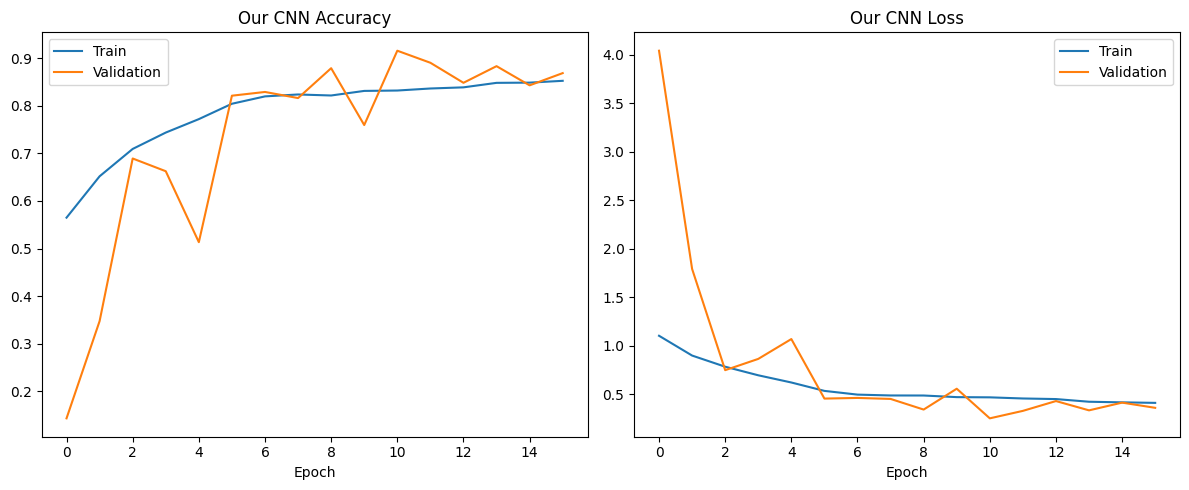

In [ ]:
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history_scratch.history["accuracy"], label="Train")
plt.plot(history_scratch.history["val_accuracy"], label="Validation")
plt.title("Our CNN Accuracy")
plt.xlabel("Epoch")
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(history_scratch.history["loss"], label="Train")
plt.plot(history_scratch.history["val_loss"], label="Validation")
plt.title("Our CNN Loss")
plt.xlabel("Epoch")
plt.legend()
plt.tight_layout()
plt.show()


Our CNN
Accuracy : 0.824
Precision: 0.8367725755790931
Recall   : 0.824
F1       : 0.82153826305901
              precision    recall  f1-score   support

   buildings       0.88      0.75      0.81       437
      forest       0.95      0.98      0.97       474
     glacier       0.84      0.75      0.79       553
    mountain       0.88      0.63      0.73       525
         sea       0.69      0.95      0.80       510
      street       0.79      0.90      0.84       501

    accuracy                           0.82      3000
   macro avg       0.84      0.83      0.82      3000
weighted avg       0.84      0.82      0.82      3000



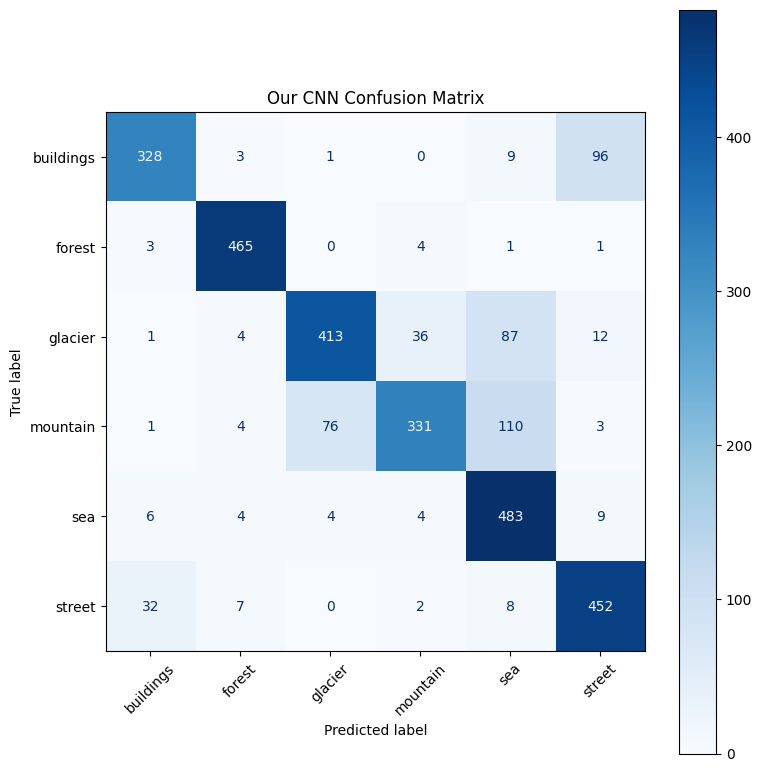

In [ ]:
y_true_scratch = []
y_pred_scratch = []

for images, labels in test_ds:
    preds = scratch_model.predict(images, verbose=0)
    y_true_scratch.extend(np.argmax(labels.numpy(), axis=1))
    y_pred_scratch.extend(np.argmax(preds, axis=1))

y_true_scratch = np.array(y_true_scratch)
y_pred_scratch = np.array(y_pred_scratch)

scratch_acc = accuracy_score(y_true_scratch, y_pred_scratch)
scratch_precision = precision_score(y_true_scratch, y_pred_scratch, average="weighted", zero_division=0)
scratch_recall = recall_score(y_true_scratch, y_pred_scratch, average="weighted", zero_division=0)
scratch_f1 = f1_score(y_true_scratch, y_pred_scratch, average="weighted", zero_division=0)

print("Our CNN")
print("Accuracy :", scratch_acc)
print("Precision:", scratch_precision)
print("Recall   :", scratch_recall)
print("F1       :", scratch_f1)
print(classification_report(y_true_scratch, y_pred_scratch, target_names=class_names, zero_division=0))

cm = confusion_matrix(y_true_scratch, y_pred_scratch)

fig, ax = plt.subplots(figsize=(8, 8))
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names).plot(ax=ax, cmap="Blues", xticks_rotation=45)
plt.title("Our CNN Confusion Matrix")
plt.tight_layout()
plt.show()


## Transfer Learning

EfficientNetB0 is the transfer model for these scene photos. The base model stays frozen in the first training. Then the last 30 layers are fine-tuned and BatchNorm stays frozen.


In [ ]:
callbacks = [
    EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
    ReduceLROnPlateau(monitor="val_loss", factor=0.2, patience=2, min_lr=1e-6),
]

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.15),
])

base_model = EfficientNetB0(weights="imagenet", include_top=False, input_shape=(224, 224, 3))
base_model.trainable = False

inputs = layers.Input(shape=(224, 224, 3))
x = data_augmentation(inputs)
# EfficientNet already scales 0-255 pixels inside the model
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.4)(x)
outputs = layers.Dense(len(class_names), activation="softmax")(x)

model = tf.keras.Model(inputs, outputs)
model.summary()


16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "functional_19"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_1 (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 6)              │         7,686 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,062,377 (15.50 MB)

 Trainable params: 10,246 (40.02 KB)

 Non-trainable params: 4,052,131 (15.46 MB)

In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)
history = model.fit(train_ds, validation_data=val_ds, epochs=12, callbacks=callbacks, verbose=1)


Epoch 1/12
351/351 ━━━━━━━━━━━━━━━━━━━━ 63s 110ms/step - accuracy: 0.8181 - loss: 0.5235 - val_accuracy: 0.9202 - val_loss: 0.2060 - learning_rate: 0.0010
Epoch 2/12
351/351 ━━━━━━━━━━━━━━━━━━━━ 46s 97ms/step - accuracy: 0.8782 - loss: 0.3532 - val_accuracy: 0.9366 - val_loss: 0.1712 - learning_rate: 0.0010
Epoch 3/12
351/351 ━━━━━━━━━━━━━━━━━━━━ 46s 98ms/step - accuracy: 0.8837 - loss: 0.3353 - val_accuracy: 0.9291 - val_loss: 0.1752 - learning_rate: 0.0010
Epoch 4/12
351/351 ━━━━━━━━━━━━━━━━━━━━ 47s 98ms/step - accuracy: 0.8887 - loss: 0.3185 - val_accuracy: 0.9440 - val_loss: 0.1460 - learning_rate: 0.0010
Epoch 5/12
351/351 ━━━━━━━━━━━━━━━━━━━━ 46s 98ms/step - accuracy: 0.8942 - loss: 0.2944 - val_accuracy: 0.9587 - val_loss: 0.1087 - learning_rate: 0.0010
Epoch 6/12
351/351 ━━━━━━━━━━━━━━━━━━━━ 46s 98ms/step - accuracy: 0.8902 - loss: 0.3013 - val_accuracy: 0.9533 - val_loss: 0.1165 - learning_rate: 0.0010
Epoch 7/12
351/351 ━━━━━━━━━━━━━━━━━━━━ 82s 99ms/step - accuracy: 0.8907 - 

In [ ]:
os.makedirs("models", exist_ok=True)
frozen_path = "models/intel_scene_frozen.keras"
model.save(frozen_path)

base_model.trainable = True
for layer in base_model.layers[:-30]:
    layer.trainable = False
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)
history_fine = model.fit(train_ds, validation_data=val_ds, epochs=8, callbacks=callbacks, verbose=1)

best_frozen = min(history.history["val_loss"])
best_fine = min(history_fine.history["val_loss"])
print("Best frozen val_loss :", best_frozen)
print("Best fine-tune val_loss:", best_fine)

if best_fine < best_frozen:
    print("Keeping the fine-tuned weights")
else:
    print("Fine-tuning did not beat the frozen model. Loading those weights back.")
    model = tf.keras.models.load_model(frozen_path)


Epoch 1/8
351/351 ━━━━━━━━━━━━━━━━━━━━ 64s 115ms/step - accuracy: 0.9061 - loss: 0.2626 - val_accuracy: 0.9594 - val_loss: 0.1072 - learning_rate: 1.0000e-05
Epoch 2/8
351/351 ━━━━━━━━━━━━━━━━━━━━ 49s 105ms/step - accuracy: 0.9086 - loss: 0.2560 - val_accuracy: 0.9672 - val_loss: 0.0888 - learning_rate: 1.0000e-05
Epoch 3/8
351/351 ━━━━━━━━━━━━━━━━━━━━ 49s 106ms/step - accuracy: 0.9085 - loss: 0.2552 - val_accuracy: 0.9644 - val_loss: 0.0941 - learning_rate: 2.0000e-06
Epoch 4/8
351/351 ━━━━━━━━━━━━━━━━━━━━ 52s 115ms/step - accuracy: 0.9085 - loss: 0.2514 - val_accuracy: 0.9619 - val_loss: 0.1002 - learning_rate: 2.0000e-06
Epoch 5/8
351/351 ━━━━━━━━━━━━━━━━━━━━ 49s 106ms/step - accuracy: 0.9106 - loss: 0.2444 - val_accuracy: 0.9644 - val_loss: 0.0937 - learning_rate: 1.0000e-06
Best frozen val_loss : 0.06632144749164581
Best fine-tune val_loss: 0.08882313966751099
Fine-tuning did not beat the frozen model. Loading those weights back.


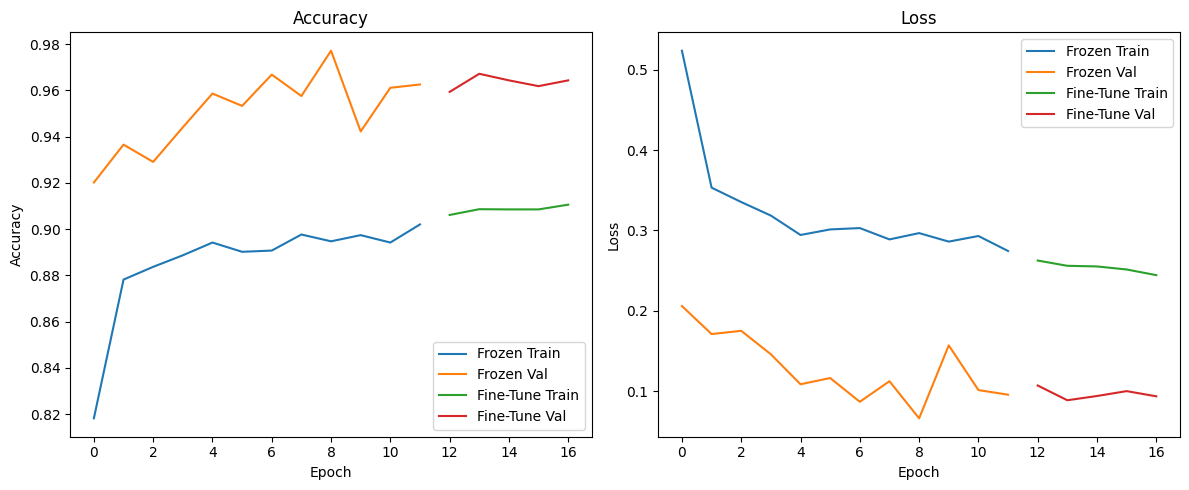

In [ ]:
stages = [(history, "Frozen"), (history_fine, "Fine-Tune")]
metrics = [("accuracy", "Accuracy"), ("loss", "Loss")]

plt.figure(figsize=(12, 5))
for i, (key, title) in enumerate(metrics, start=1):
    plt.subplot(1, 2, i)
    start = 0
    for hist, name in stages:
        y_train = hist.history[key]
        y_val = hist.history["val_" + key]
        epochs = range(start, start + len(y_train))
        plt.plot(epochs, y_train, label=name + " Train")
        plt.plot(epochs, y_val, label=name + " Val")
        start += len(y_train)
    plt.xlabel("Epoch")
    plt.ylabel(title)
    plt.title(title)
    plt.legend()
plt.tight_layout()
plt.show()


Accuracy : 0.9173333333333333
Precision: 0.9169434675864929
Recall   : 0.9173333333333333
F1       : 0.9167609353575681
              precision    recall  f1-score   support

   buildings       0.94      0.89      0.92       437
      forest       0.99      0.99      0.99       474
     glacier       0.87      0.85      0.86       553
    mountain       0.87      0.84      0.86       525
         sea       0.93      0.99      0.96       510
      street       0.91      0.95      0.93       501

    accuracy                           0.92      3000
   macro avg       0.92      0.92      0.92      3000
weighted avg       0.92      0.92      0.92      3000



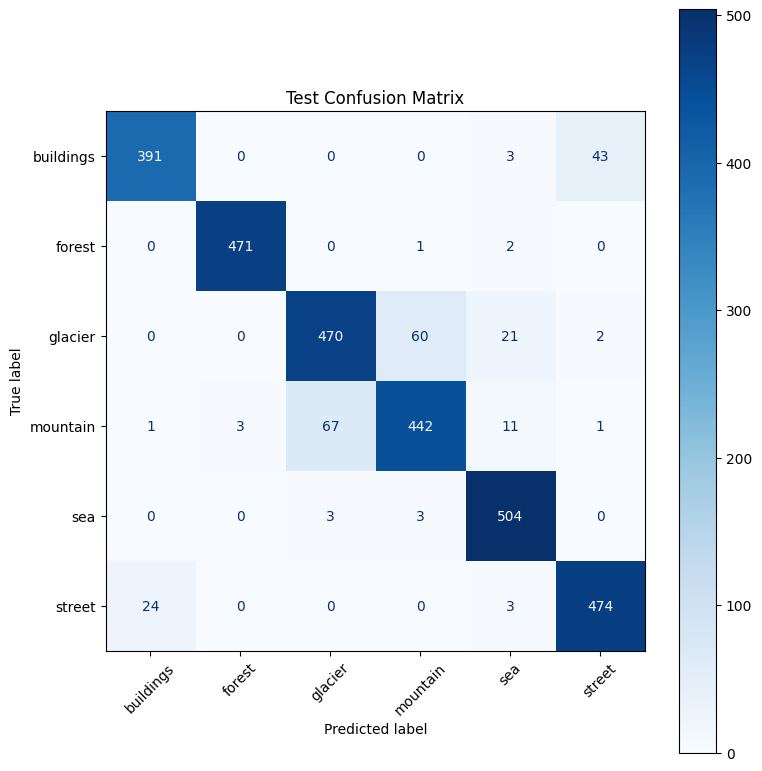

In [ ]:
y_true = []
y_pred = []

for images, labels in test_ds:
    preds = model.predict(images, verbose=0)
    y_true.extend(np.argmax(labels.numpy(), axis=1))
    y_pred.extend(np.argmax(preds, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("Accuracy :", accuracy_score(y_true, y_pred))
print("Precision:", precision_score(y_true, y_pred, average="weighted", zero_division=0))
print("Recall   :", recall_score(y_true, y_pred, average="weighted", zero_division=0))
print("F1       :", f1_score(y_true, y_pred, average="weighted", zero_division=0))
print(classification_report(y_true, y_pred, target_names=class_names, zero_division=0))

cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(8, 8))
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names).plot(
    ax=ax, cmap="Blues", xticks_rotation=45
)
plt.title("Test Confusion Matrix")
plt.tight_layout()
plt.show()

transfer_acc = accuracy_score(y_true, y_pred)
transfer_f1 = f1_score(y_true, y_pred, average="weighted", zero_division=0)


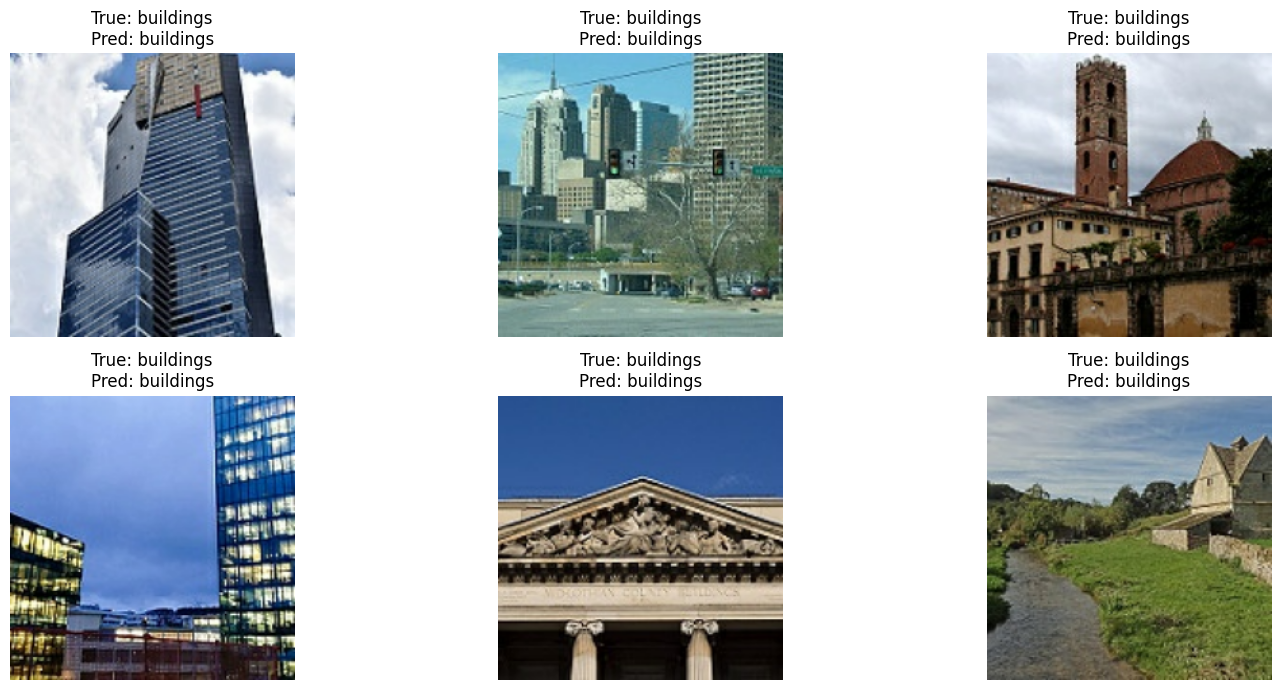

In [ ]:
images, labels = next(iter(test_ds))
pred = model.predict(images, verbose=0)

plt.figure(figsize=(16, 7))
for i in range(6):
    plt.subplot(2, 3, i + 1)
    plt.imshow(images[i].numpy().astype("uint8"))
    actual = class_names[np.argmax(labels[i])]
    guessed = class_names[np.argmax(pred[i])]
    plt.title("True: " + actual + "\nPred: " + guessed)
    plt.axis("off")
plt.tight_layout()
plt.show()


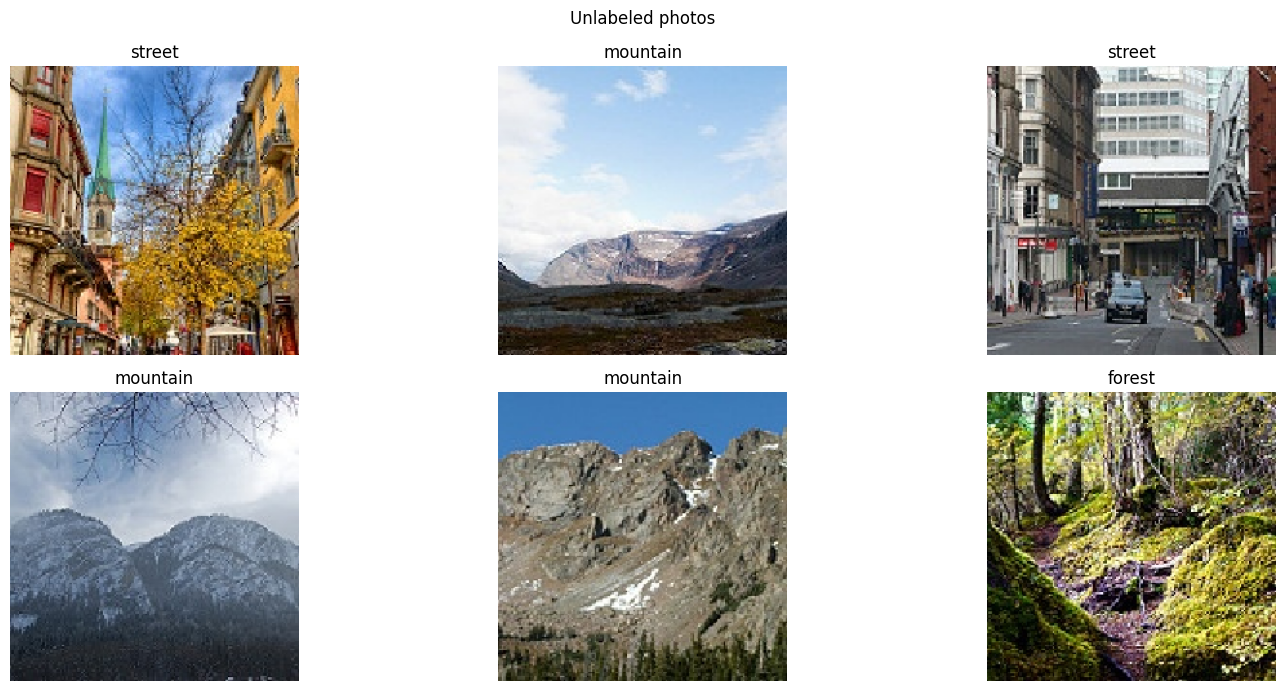

In [ ]:
pred_dir = next(current for current, dirnames, files in os.walk(path) if files and not dirnames and "pred" in current.lower())
names = sorted(os.listdir(pred_dir))[:6]
batch = np.array([tf.keras.utils.img_to_array(tf.keras.utils.load_img(os.path.join(pred_dir, name), target_size=IMG_SIZE)) for name in names])
guessed = model.predict(batch, verbose=0)

plt.figure(figsize=(16, 7))
for i in range(6):
    plt.subplot(2, 3, i + 1)
    plt.imshow(batch[i].astype("uint8"))
    plt.title(class_names[np.argmax(guessed[i])])
    plt.axis("off")
plt.suptitle("Unlabeled photos")
plt.tight_layout()
plt.show()


## Comparison


In [ ]:
print("Our CNN   Accuracy:", round(scratch_acc, 4), " F1:", round(scratch_f1, 4))
print("Transfer  Accuracy:", round(transfer_acc, 4), " F1:", round(transfer_f1, 4))


Our CNN   Accuracy: 0.824  F1: 0.8215
Transfer  Accuracy: 0.9173  F1: 0.9168


In [ ]:
model.save("intel_scene.keras")


# Conclusion

Our own CNN and EfficientNetB0 were trained on the same split. The comparison cell prints both accuracy and F1 scores. EfficientNetB0 already knows general shapes from ImageNet, so scenes like forest, sea and mountain should be easier for it. Glacier and mountain, and also buildings and street, are the pairs to check in the confusion matrix. The unlabeled seg_pred plot uses the transfer model, so those titles are guesses, not true labels. The model is saved as intel_scene.keras.
